# 02 店舗・メニュー・価格・キャンペーン・カレンダーの EDA

全 CSV を対象に、列、欠損、予定期間、結合キー、有効期間を確認する。集計の差は相関であり施策の因果効果ではない。価格と席の有効期間は両端を含む。パイプ区切りの店舗一覧と `all` を正しく展開する。

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / "input").is_dir():
    ROOT = ROOT.parent
assert (ROOT / "input").is_dir(), "プロジェクトルートまたは eda/ から実行してください"
INPUT = ROOT / "input"
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 100)
pd.options.display.float_format = "{:,.2f}".format
sns.set_theme(style="whitegrid", font_scale=0.9)
plt.rcParams["figure.figsize"] = (12, 4)


In [2]:
names = ["stores","seat_layout","menus","menu_catalog_history","price_history","campaign_calendar","calendar"]
tables = {name: pd.read_csv(INPUT / f"{name}.csv") for name in names}
for name, df in tables.items():
    print(f"\n{name}: {df.shape}, duplicate full rows={df.duplicated().sum()}")
    display(pd.DataFrame({"dtype":df.dtypes.astype(str),"missing":df.isna().sum(),"distinct":df.nunique()}))
    display(df.head(3))


stores: (10, 7), duplicate full rows=0

seat_layout: (36, 9), duplicate full rows=0

menus: (84, 7), duplicate full rows=0

menu_catalog_history: (150, 4), duplicate full rows=0

price_history: (1075, 5), duplicate full rows=0

campaign_calendar: (4005, 10), duplicate full rows=0

calendar: (1461, 8), duplicate full rows=0


,dtype,missing,distinct
store_id,str,0,10
store_name,str,0,10
area_type,str,0,5
floor_area,float64,0,10
opening_date,str,0,10
business_start_time,str,0,1
business_end_time,str,0,1


,store_id,store_name,area_type,floor_area,opening_date,business_start_time,business_end_time
0,S001,Family Diner 001,urban_core,323.90,2015-09-14,10:00,23:00
1,S002,Family Diner 002,office,365.00,2015-12-19,10:00,23:00
2,S003,Family Diner 003,suburban_sc,429.60,2019-12-27,10:00,23:00


,dtype,missing,distinct
store_id,str,0,10
layout_version,str,0,3
effective_start_date,str,0,18
effective_end_date,str,0,18
num_table_1p,int64,0,6
num_table_2p,int64,0,8
num_table_4p,int64,0,9
num_table_6p,int64,0,7
total_seats,int64,0,3


,store_id,layout_version,effective_start_date,effective_end_date,num_table_1p,num_table_2p,num_table_4p,num_table_6p,total_seats
0,S001,L01,2022-01-01,2023-04-14,0,6,15,3,90
1,S001,L02,2023-04-15,2024-12-31,8,20,12,2,108
2,S001,L02,2025-01-01,2025-03-14,8,20,12,2,108


,dtype,missing,distinct
item_id,str,0,84
item_name,str,0,84
category,str,0,6
available_daypart,str,0,2
menu_type,str,0,3
season_code,str,71,4
campaign_tag,str,72,4


... (5 outputs left out)

,dtype,missing,distinct
date,str,0,1461
campaign_id,str,0,34
campaign_name,str,0,26
campaign_type,str,0,7
coupon_flag,bool,0,2
discount_rate,float64,0,6
target_item_group,str,0,6
target_area_type,str,0,3
collaboration_partner,str,3573,4
store_ids,str,0,149


,date,campaign_id,campaign_name,campaign_type,coupon_flag,discount_rate,target_item_group,target_area_type,collaboration_partner,store_ids
0,2022-01-01,RULE_FAMILY_WEEKEND,Family Weekend Fair,family_weekend,True,0.10,main,suburban_sc|roadside,NaN,S004
1,2022-01-01,SEASONAL_2021_WINTER,Winter Seasonal Fair 2021-2022,seasonal_fair,False,0.00,seasonal,all,NaN,all
2,2022-01-02,RULE_DESSERT_FAIR,Dessert Fair,dessert_fair,True,0.07,dessert,all,NaN,S002|S006|S010


,dtype,missing,distinct
date,str,0,1461
is_holiday,bool,0,2
weather_observed,str,365,4
temperature_observed,float64,365,330
precipitation_observed,float64,365,192
temperature_normal,float64,0,476
wet_probability_normal,float64,0,401
precipitation_normal,float64,0,259


,date,is_holiday,weather_observed,temperature_observed,precipitation_observed,temperature_normal,wet_probability_normal,precipitation_normal
0,2022-01-01,True,sunny,6.00,0.00,5.72,0.25,3.26
1,2022-01-02,False,sunny,4.00,0.00,5.62,0.25,3.26
2,2022-01-03,False,sunny,5.80,0.00,5.51,0.25,3.26


## 店舗と席レイアウト

Duplicate stores/items: 0 0
Unknown store / item references: 0 0 0
Seat total discrepancies: 0


,store_id,store_name,area_type,floor_area,opening_date,business_start_time,business_end_time
0,S001,Family Diner 001,urban_core,323.90,2015-09-14,10:00,23:00
1,S002,Family Diner 002,office,365.00,2015-12-19,10:00,23:00
2,S003,Family Diner 003,suburban_sc,429.60,2019-12-27,10:00,23:00
3,S004,Family Diner 004,suburban_sc,358.10,2020-04-23,10:00,23:00
4,S005,Family Diner 005,roadside,363.50,2013-03-05,10:00,23:00
5,S006,Family Diner 006,residential,340.30,2014-03-07,10:00,23:00
6,S007,Family Diner 007,residential,282.30,2015-06-15,10:00,23:00
7,S008,Family Diner 008,office,357.60,2017-06-10,10:00,23:00
8,S009,Family Diner 009,roadside,306.30,2013-08-01,10:00,23:00
9,S010,Family Diner 010,urban_core,271.90,2018-11-19,10:00,23:00


,store_id,layout_version,effective_start_date,effective_end_date,num_table_1p,num_table_2p,num_table_4p,num_table_6p,total_seats
0,S001,L01,2022-01-01,2023-04-14,0,6,15,3,90
1,S001,L02,2023-04-15,2024-12-31,8,20,12,2,108
2,S001,L02,2025-01-01,2025-03-14,8,20,12,2,108
3,S001,L03,2025-03-15,2025-12-31,10,20,13,3,120
4,S002,L01,2022-01-01,2023-09-14,4,12,14,1,90
5,S002,L02,2023-09-15,2024-12-31,8,16,8,3,90
6,S002,L02,2025-01-01,2025-09-14,8,16,8,3,90
7,S002,L03,2025-09-15,2025-12-31,8,20,12,2,108
8,S003,L01,2022-01-01,2023-05-14,14,16,11,0,90
9,S003,L02,2023-05-15,2024-12-31,4,8,10,5,90


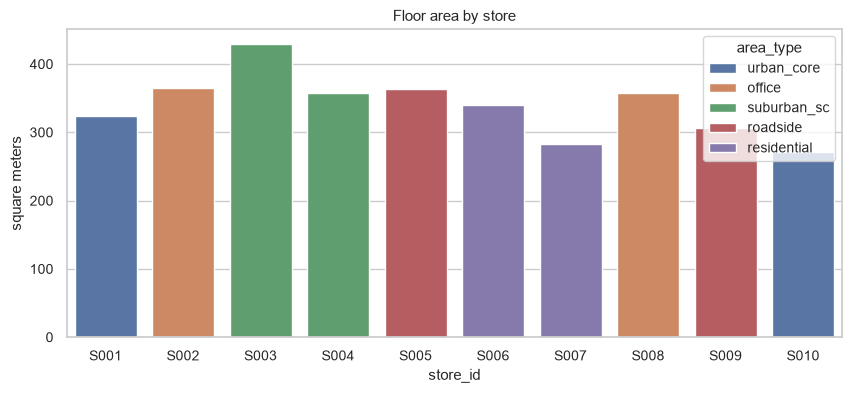

In [3]:
stores, seats, menus, catalog, prices, campaigns, calendar = (tables[n].copy() for n in names)
print("Duplicate stores/items:", stores.store_id.duplicated().sum(), menus.item_id.duplicated().sum())
print("Unknown store / item references:", (~seats.store_id.isin(stores.store_id)).sum(), (~catalog.item_id.isin(menus.item_id)).sum(), (~prices.item_id.isin(menus.item_id)).sum())
display(stores)
display(seats.sort_values(["store_id","effective_start_date"]))
seats["calculated_seats"] = sum(seats[f"num_table_{n}p"] * n for n in [1,2,4,6])
print("Seat total discrepancies:", int((seats.calculated_seats != seats.total_seats).sum()))
fig,ax=plt.subplots(figsize=(10,4)); sns.barplot(data=stores,x="store_id",y="floor_area",hue="area_type",dodge=False,ax=ax); ax.set(title="Floor area by store",ylabel="square meters"); plt.show()

## 商品と販売期間

In [4]:
display(pd.crosstab(menus.category, menus.menu_type, margins=True))
display(pd.crosstab(menus.available_daypart, menus.menu_type, margins=True))
for frame in [catalog,seats,prices]:
    for col in ["effective_start_date","effective_end_date"]: frame[col]=pd.to_datetime(frame[col])

def expand_intervals(frame, keys):
    """両端を含む日付に展開。小さいマスタ用。"""
    x=frame.copy(); x["date"]=[pd.date_range(a,b) for a,b in zip(x.effective_start_date,x.effective_end_date)]
    return x.explode("date",ignore_index=True)

catalog_days = expand_intervals(catalog, ["item_id"])
print("Catalog overlapping item-day rows:", catalog_days.duplicated(["item_id","date"]).sum())
train=pd.read_csv(INPUT / "train.csv",parse_dates=["date"])
active=catalog_days[["item_id","date"]].drop_duplicates().assign(active=True)
sales_active=train.merge(active,on=["item_id","date"],how="left",validate="many_to_one")
sales_active["active"]=sales_active.active.fillna(False).astype(bool)
display(sales_active.groupby("active").sales_amount.agg(rows="size",positive_rows=lambda x:(x>0).sum(),zero_fraction=lambda x:(x==0).mean(),total="sum"))
print("販売期間外の売上が正の行:", int(((~sales_active.active)&(sales_active.sales_amount>0)).sum()))
display(catalog.assign(year=catalog.effective_start_date.dt.year).groupby("year").size().rename("periods"))

Catalog overlapping item-day rows: 0
販売期間外の売上が正の行: 0


menu_type,collaboration,core,seasonal,All
category,,,,
dessert,4,12,4,20
drink_bar,0,2,0,2
kids,2,6,0,8
lunch,0,12,0,12
main,4,15,8,27
side,2,12,1,15
All,12,59,13,84


menu_type,collaboration,core,seasonal,All
available_daypart,,,,
all_day,12,47,13,72
lunch,0,12,0,12
All,12,59,13,84


,rows,positive_rows,zero_fraction,total
active,,,,
False,228640,0,1.00,0.00
True,692000,676728,0.02,"6,255,595,849.00"


year
2022    84
2023    22
2024    22
2025    22
Name: periods, dtype: int64

## 価格・席の期間カバレッジ
`all` は10店舗に展開し、同一キーでの重複・欠落を確認する。特定店舗に複数価格がある場合は勝手に優先順位を付けない。

In [5]:
store_ids=stores.store_id.tolist()
def explode_stores(frame):
    x=frame.copy(); x["store_id"]=x.store_ids.map(lambda s: store_ids if s=="all" else str(s).split("|")); return x.explode("store_id",ignore_index=True)
price_days=expand_intervals(explode_stores(prices), ["item_id","store_id"])
seat_days=expand_intervals(seats,["store_id"])
for label, df, keys in [("price",price_days,["date","store_id","item_id"]),("seat",seat_days,["date","store_id"])]:
    print(label,"unknown stores:", int((~df.store_id.isin(store_ids)).sum()),"duplicate effective keys:",int(df.duplicated(keys).sum()),"period:",df.date.min(),df.date.max())
all_keys=pd.concat([train[["date","store_id","item_id"]],pd.read_csv(INPUT/"test.csv",parse_dates=["date"])[["date","store_id","item_id"]]],ignore_index=True)
price_keys=price_days[["date","store_id","item_id"]].drop_duplicates().assign(has_price=True)
coverage=all_keys.merge(price_keys,on=["date","store_id","item_id"],how="left",validate="one_to_one")
print("price missing over train/test keys:",int(coverage.has_price.isna().sum()))
seat_keys=seat_days[["date","store_id"]].drop_duplicates().assign(has_seat=True)
print("seat missing over train/test store-days:",int(all_keys[["date","store_id"]].drop_duplicates().merge(seat_keys,on=["date","store_id"],how="left",validate="one_to_one").has_seat.isna().sum()))
display(prices.groupby(prices.effective_start_date.dt.year).selling_price.agg(["count","min","median","max"]))
display(prices.sort_values("effective_start_date").head())

price unknown stores: 0 duplicate effective keys: 0 period: 2022-01-01 00:00:00 2025-12-31 00:00:00
seat unknown stores: 0 duplicate effective keys: 0 period: 2022-01-01 00:00:00 2025-12-31 00:00:00
price missing over train/test keys: 0
seat missing over train/test store-days: 0


,count,min,median,max
effective_start_date,,,,
2022,84,250,735.00,1220
2024,352,250,840.00,1350
2025,639,250,890.00,1410


,item_id,store_ids,effective_start_date,effective_end_date,selling_price
0,M001,all,2022-01-01,2024-03-31,340
262,M020,all,2022-01-01,2024-03-31,750
277,M021,all,2022-01-01,2024-03-31,820
905,M073,all,2022-01-01,2024-03-31,790
292,M022,all,2022-01-01,2024-03-31,750


## キャンペーンとカレンダー

duplicate campaign/date rows: 0
unknown campaign store entries: 0
Multiple campaigns per store/day are expected: 7728
Duplicate dates: 0


rows  days  avg_discount
date campaign_type                           
2022 collaboration    108   108          0.00
     dessert_fair     202   202          0.07
     family_weekend    72    72          0.10
     kids_campaign     84    84          0.05
     rainy_season      45    45          0.06
     seasonal_fair    365   365          0.00
     weekday_lunch    103   103          0.08
2023 collaboration    108   108          0.00
     dessert_fair     206   206          0.07
     family_weekend    84    84          0.10
     kids_campaign     88    88          0.05
     rainy_season      45    45          0.06
     seasonal_fair    365   365          0.00
     weekday_lunch    109   109          0.08
2024 collaboration    108   108          0.00
     dessert_fair     207   207          0.07
     family_weekend    85    85          0.10
     kids_campaign     93    93          0.05
     rainy_season      45    45          0.06
     seasonal_fair    366   366          0.00
     weekday_lunch     99    99          0.08
2025 collaboration    108   108          0.00
     dessert_fair     213   213          0.07
     family_weekend    87    87          0.10
     kids_campaign     95    95          0.05
     rainy_season      45    45          0.06
     seasonal_fair    365   365          0.00
     weekday_lunch    105   105          0.08

,days,holidays,weather_missing,temperature_missing,precipitation_missing,normal_temperature_missing
year,,,,,,
2022,365,16,0,0,0,0
2023,365,17,0,0,0,0
2024,366,21,0,0,0,0
2025,365,19,365,365,365,0


,count,mean,median
weather_observed,,,
cloudy,278,"5,767,064.58","5,704,832.00"
rainy,346,"5,526,553.54","5,397,174.00"
snowy,5,"5,624,547.20","5,544,370.00"
sunny,467,"5,807,369.67","5,733,530.00"


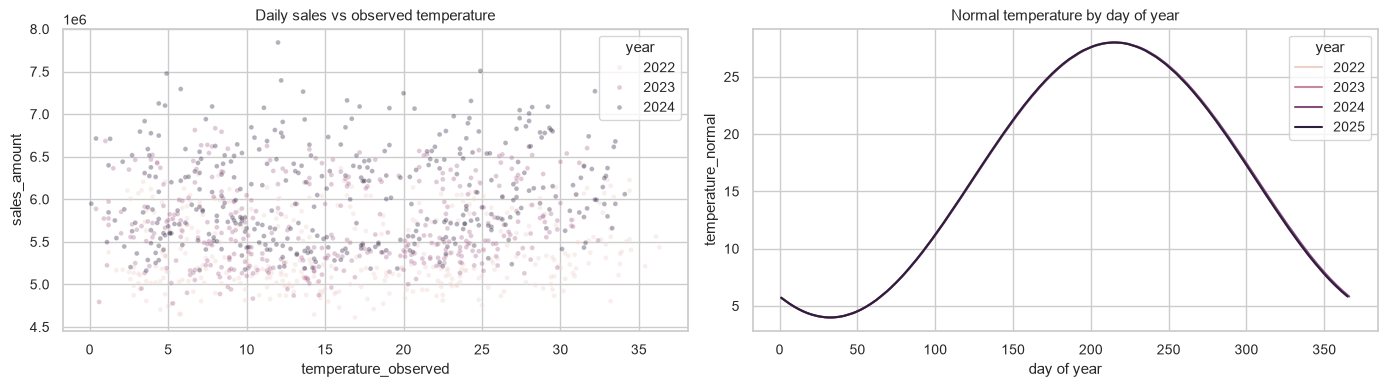

In [6]:
campaigns["date"]=pd.to_datetime(campaigns.date)
display(campaigns.groupby([campaigns.date.dt.year,"campaign_type"],observed=True).agg(rows=("campaign_id","size"),days=("date","nunique"),avg_discount=("discount_rate","mean")))
print("duplicate campaign/date rows:",campaigns.duplicated(["date","campaign_id"]).sum())
ce=explode_stores(campaigns); print("unknown campaign store entries:",int((~ce.store_id.isin(store_ids)).sum()))
print("Multiple campaigns per store/day are expected:",int(ce.duplicated(["date","store_id"]).sum()))
calendar["date"]=pd.to_datetime(calendar.date)
print("Duplicate dates:",calendar.date.duplicated().sum())
calendar["year"]=calendar.date.dt.year
display(calendar.groupby("year").agg(days=("date","size"), holidays=("is_holiday","sum"), weather_missing=("weather_observed",lambda x:x.isna().sum()), temperature_missing=("temperature_observed",lambda x:x.isna().sum()), precipitation_missing=("precipitation_observed",lambda x:x.isna().sum()), normal_temperature_missing=("temperature_normal",lambda x:x.isna().sum())))
daily=train.groupby("date",as_index=False).sales_amount.sum().merge(calendar,on="date",validate="one_to_one")
display(daily.groupby("weather_observed",dropna=False).sales_amount.agg(["count","mean","median"]))
fig,ax=plt.subplots(1,2,figsize=(14,4)); sns.scatterplot(data=daily,x="temperature_observed",y="sales_amount",hue="year",alpha=.35,s=12,ax=ax[0]); ax[0].set(title="Daily sales vs observed temperature"); sns.lineplot(data=calendar,x=calendar.date.dt.dayofyear,y="temperature_normal",hue="year",ax=ax[1],errorbar=None); ax[1].set(title="Normal temperature by day of year",xlabel="day of year"); plt.tight_layout(); plt.show()

## 解釈・利用可能時点
- 2025 年の天候実績列は空欄。観測値と平年値を混同しない。
- 価格、販売期間、キャンペーン、席レイアウトには 2025 年の計画が含まれる。日付の範囲・店舗条件・複数施策を守って結合する。
- 祝日、天候、曜日、季節、店舗、キャンペーンは相関するため、単純集計だけで効果を断定しない。